<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP8_DeepLearning_TrackB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MP8 · Track B — Forecasting tomorrow's AQI in Delhi (RNN and LSTM)
Naive and linear baselines first, then a SimpleRNN and an LSTM. Time-based split: train ≤ 2021, validation = 2022, test = 2023 (opened once, at the end).

In [15]:
import os, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

tf.random.set_seed(42); np.random.seed(42); random.seed(42)

# Load the CSV: upload it in Colab, or read it directly if it is already in the folder
CSV = "mp8_trackB_delhi_daily_aqi.csv"
if not os.path.exists(CSV):
    try:
        from google.colab import files
        files.upload()          # choose mp8_trackB_delhi_daily_aqi.csv
    except ImportError:
        CSV = "/mnt/user-data/uploads/mp8_trackB_delhi_daily_aqi.csv"
df = pd.read_csv(CSV)
print(df.shape); df.head()

(3143, 2)


,date,aqi
0,2015-05-01,221
1,2015-05-02,238
2,2015-05-03,259
3,2015-05-04,289
4,2015-05-05,311


## B1 · Prepare the series

In [16]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date").sort_index()
print("Rows before filling:", len(df), "| range:", df.index.min().date(), "to", df.index.max().date())
df = df.asfreq("D")
print("Missing days after asfreq:", df["aqi"].isna().sum())
df["aqi"] = df["aqi"].interpolate()
print("Missing after interpolate:", df["aqi"].isna().sum(), "| rows:", len(df))
df.describe()

Rows before filling: 3143 | range: 2015-05-01 to 2023-12-31
Missing days after asfreq: 24
Missing after interpolate: 0 | rows: 3167


,aqi
count,3167.000000
mean,216.987212
std,103.784629
min,41.000000
25%,127.500000
50%,208.000000
75%,296.000000
max,497.000000


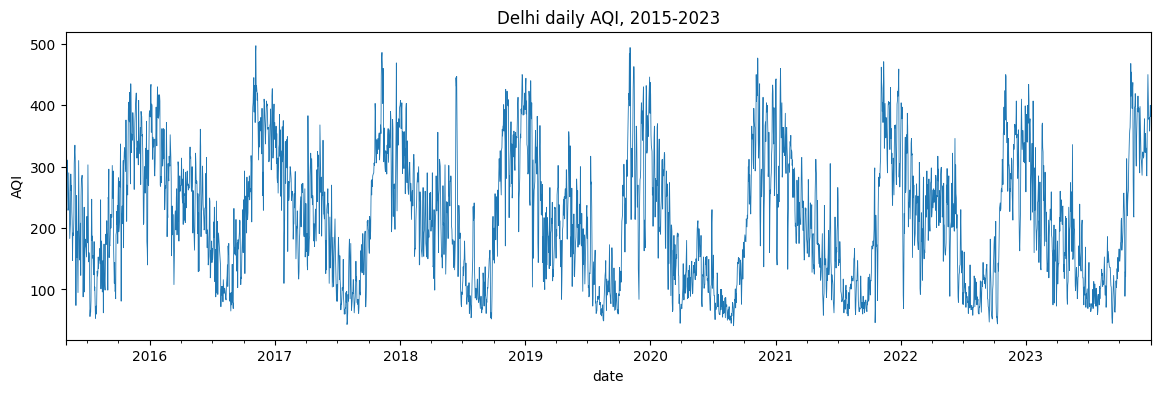

Mean AQI by month:
 date
1     316.0
2     255.0
3     196.0
4     210.0
5     205.0
6     173.0
7     110.0
8     104.0
9     124.0
10    244.0
11    349.0
12    335.0


In [17]:
fig, ax = plt.subplots(figsize=(14,4))
df["aqi"].plot(ax=ax, lw=0.6)
ax.set_title("Delhi daily AQI, 2015-2023"); ax.set_ylabel("AQI"); plt.show()

monthly = df.groupby(df.index.month)["aqi"].mean().round(0)
print("Mean AQI by month:\n", monthly.to_string())

**Yearly pattern (one sentence):** Delhi's AQI follows a strong seasonal cycle — it climbs through October–January (stubble burning, Diwali, cold still air and inversions) to peak around November, then falls to its lowest in the monsoon months of July–September.

In [18]:
train = df.loc[:"2021"].copy(); val = df.loc["2022"].copy(); test = df.loc["2023"].copy()
print("train", train.shape, "| val", val.shape, "| test", test.shape)

# Scale with TRAIN statistics only
mu, sd = train["aqi"].mean(), train["aqi"].std()
print(f"train mean = {mu:.2f}, train std = {sd:.2f}")
df["scaled"] = (df["aqi"] - mu) / sd

train (2437, 1) | val (365, 1) | test (365, 1)
train mean = 220.15, train std = 104.24


## B2 · 14-day windows

In [19]:
WINDOW = 14
def make_windows(values):
    X, y = [], []
    for i in range(WINDOW, len(values)):
        X.append(values[i - WINDOW:i])
        y.append(values[i])
    return np.array(X)[..., None], np.array(y)

X_train, y_train = make_windows(df.loc[:"2021", "scaled"].values)
X_val,   y_val   = make_windows(df.loc["2021-12-18":"2022-12-31", "scaled"].values)
X_test,  y_test  = make_windows(df.loc["2022-12-18":"2023-12-31", "scaled"].values)
for n, a in [("X_train",X_train),("y_train",y_train),("X_val",X_val),("y_val",y_val),("X_test",X_test),("y_test",y_test)]:
    print(n, a.shape)

X_train (2423, 14, 1)
y_train (2423,)
X_val (365, 14, 1)
y_val (365,)
X_test (365, 14, 1)
y_test (365,)


Checks: validation has 365 windows (all of 2022) and test has 365 (all of 2023), so every day of those years is predicted using the 14 days before it.

## B3 · Two baselines, then two networks

In [20]:
# 1. Naive: tomorrow = today (last value of each window)
pred_naive_val  = X_val[:, -1, 0];  pred_naive_test = X_test[:, -1, 0]

# 2. Linear regression on the 14 values
lr = LinearRegression().fit(X_train.reshape(len(X_train), -1), y_train)
pred_lr_val  = lr.predict(X_val.reshape(len(X_val), -1))
pred_lr_test = lr.predict(X_test.reshape(len(X_test), -1))

def mae_aqi(y_scaled, p_scaled):   # MAE in AQI points
    return mean_absolute_error(y_scaled*sd+mu, p_scaled*sd+mu)
print("Validation MAE (AQI points)")
print("  Naive            :", round(mae_aqi(y_val, pred_naive_val), 2))
print("  Linear regression:", round(mae_aqi(y_val, pred_lr_val), 2))

Validation MAE (AQI points)
  Naive            : 33.64
  Linear regression: 33.23


In [21]:
def build(kind):
    tf.random.set_seed(42); np.random.seed(42); random.seed(42)
    rnn = layers.SimpleRNN(32) if kind == "rnn" else layers.LSTM(32)
    m = keras.Sequential([layers.Input(shape=(WINDOW, 1)), rnn, layers.Dense(1)])
    m.compile(optimizer="adam", loss="mse")
    return m

es = lambda: keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

rnn_model = build("rnn")
h_rnn = rnn_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=40, batch_size=32, callbacks=[es()], verbose=2)
rnn_model.summary()

Epoch 1/40
76/76 - 1s - 15ms/step - loss: 0.2728 - val_loss: 0.1885
Epoch 2/40
76/76 - 0s - 3ms/step - loss: 0.2035 - val_loss: 0.1813
Epoch 3/40
76/76 - 0s - 3ms/step - loss: 0.2000 - val_loss: 0.1814
Epoch 4/40
76/76 - 0s - 3ms/step - loss: 0.1990 - val_loss: 0.1814
Epoch 5/40
76/76 - 0s - 3ms/step - loss: 0.1983 - val_loss: 0.1813
Epoch 6/40
76/76 - 0s - 3ms/step - loss: 0.1977 - val_loss: 0.1812
Epoch 7/40
76/76 - 0s - 4ms/step - loss: 0.1972 - val_loss: 0.1812
Epoch 8/40
76/76 - 0s - 4ms/step - loss: 0.1968 - val_loss: 0.1813
Epoch 9/40
76/76 - 0s - 3ms/step - loss: 0.1964 - val_loss: 0.1813
Epoch 10/40
76/76 - 0s - 3ms/step - loss: 0.1960 - val_loss: 0.1814
Epoch 11/40
76/76 - 0s - 3ms/step - loss: 0.1957 - val_loss: 0.1814


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,365 (13.15 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,244 (8.77 KB)

In [22]:
lstm_model = build("lstm")
h_lstm = lstm_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=40, batch_size=32, callbacks=[es()], verbose=2)
lstm_model.summary()

Epoch 1/40
76/76 - 1s - 20ms/step - loss: 0.3844 - val_loss: 0.2773
Epoch 2/40
76/76 - 0s - 6ms/step - loss: 0.2639 - val_loss: 0.2418
Epoch 3/40
76/76 - 1s - 7ms/step - loss: 0.2330 - val_loss: 0.2044
Epoch 4/40
76/76 - 0s - 7ms/step - loss: 0.2102 - val_loss: 0.1860
Epoch 5/40
76/76 - 0s - 4ms/step - loss: 0.2000 - val_loss: 0.1790
Epoch 6/40
76/76 - 0s - 4ms/step - loss: 0.1962 - val_loss: 0.1771
Epoch 7/40
76/76 - 0s - 4ms/step - loss: 0.1947 - val_loss: 0.1767
Epoch 8/40
76/76 - 0s - 4ms/step - loss: 0.1941 - val_loss: 0.1767
Epoch 9/40
76/76 - 0s - 4ms/step - loss: 0.1938 - val_loss: 0.1767
Epoch 10/40
76/76 - 0s - 4ms/step - loss: 0.1937 - val_loss: 0.1767
Epoch 11/40
76/76 - 0s - 4ms/step - loss: 0.1935 - val_loss: 0.1767
Epoch 12/40
76/76 - 0s - 4ms/step - loss: 0.1934 - val_loss: 0.1766
Epoch 13/40
76/76 - 0s - 4ms/step - loss: 0.1934 - val_loss: 0.1766
Epoch 14/40
76/76 - 0s - 4ms/step - loss: 0.1933 - val_loss: 0.1767
Epoch 15/40
76/76 - 0s - 4ms/step - loss: 0.1932 - val_l

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,157 (51.40 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,772 (34.27 KB)

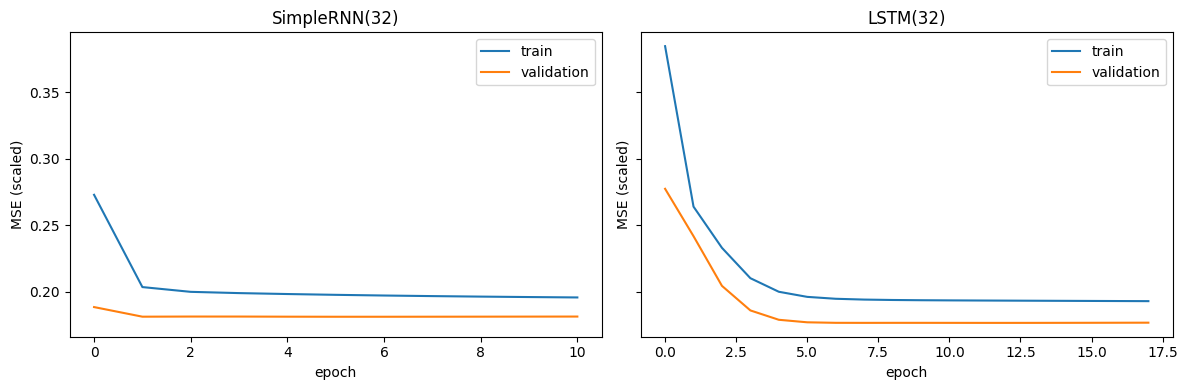

SimpleRNN: stopped after 11 epochs; best val loss 0.1812
LSTM     : stopped after 18 epochs; best val loss 0.1766


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharey=True)
for ax, h, t in [(axes[0], h_rnn, "SimpleRNN(32)"), (axes[1], h_lstm, "LSTM(32)")]:
    ax.plot(h.history["loss"], label="train"); ax.plot(h.history["val_loss"], label="validation")
    ax.set_title(t); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend()
plt.tight_layout(); plt.show()
print("SimpleRNN: stopped after", len(h_rnn.history["loss"]), "epochs; best val loss", round(min(h_rnn.history["val_loss"]),4))
print("LSTM     : stopped after", len(h_lstm.history["loss"]), "epochs; best val loss", round(min(h_lstm.history["val_loss"]),4))

**Reading the curves:** Both networks learn fast and then flatten. The SimpleRNN's validation loss bottoms out at about 0.181 by epoch 6 and training stopped at epoch 11. The LSTM reaches about 0.177 by epoch 7 and early stopping ended it at epoch 18, restoring the best weights. Training and validation loss stay close, so there is no overfitting. Both curves flatten early because the next-day AQI is mostly "today's AQI plus noise" and there is little extra signal to learn.

(Validation loss is lower than training loss because 2022 was a calmer year than the 2015–2021 training period, not because of any leak.)

## B4 · Compare honestly (test set 2023, opened once)

In [24]:
pred_rnn_test  = rnn_model.predict(X_test, verbose=0).ravel()
pred_lstm_test = lstm_model.predict(X_test, verbose=0).ravel()

# Back to AQI units: multiply by train std, add train mean
to_aqi = lambda a: a*sd + mu
actual = to_aqi(y_test)
preds = {"Naive (tomorrow = today)": to_aqi(pred_naive_test),
         "Linear regression":        to_aqi(pred_lr_test),
         "SimpleRNN(32)":            to_aqi(pred_rnn_test),
         "LSTM(32)":                 to_aqi(pred_lstm_test)}
params = {"Naive (tomorrow = today)": 0, "Linear regression": 15,
          "SimpleRNN(32)": rnn_model.count_params(), "LSTM(32)": lstm_model.count_params()}
table = pd.DataFrame({"Model": list(preds),
                      "Test MAE (AQI points)": [round(mean_absolute_error(actual, p), 2) for p in preds.values()],
                      "Parameters": [params[k] for k in preds]}).set_index("Model")
table

,Test MAE (AQI points),Parameters
Model,,
Naive (tomorrow = today),32.64,0
Linear regression,31.40,15
SimpleRNN(32),32.33,1121
LSTM(32),31.34,4385


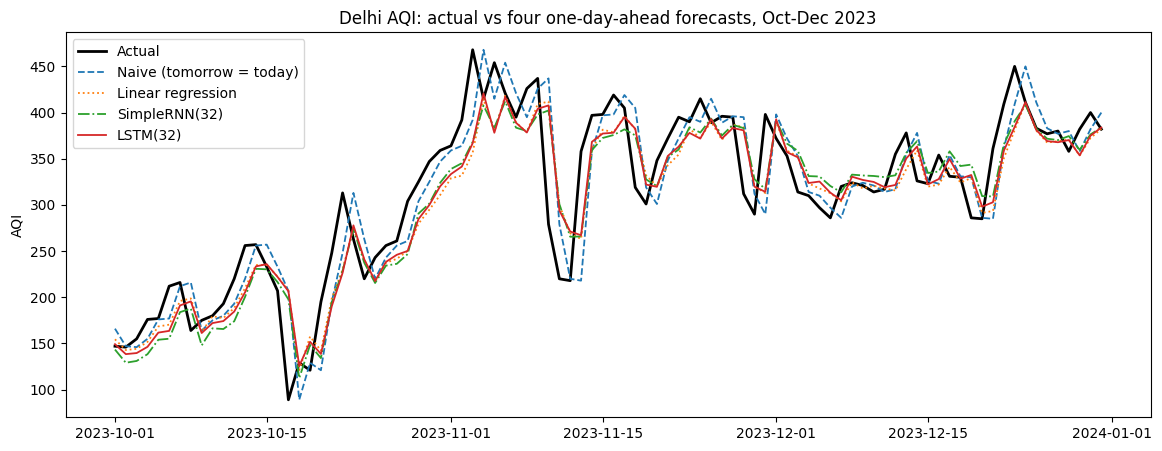

In [25]:
dates = df.loc["2023-01-01":"2023-12-31"].index
res = pd.DataFrame({"actual": actual, **{k: v for k, v in preds.items()}}, index=dates)
q4 = res.loc["2023-10-01":"2023-12-31"]
plt.figure(figsize=(14,5))
plt.plot(q4.index, q4["actual"], "k", lw=2, label="Actual")
for c, s in zip(q4.columns[1:], ["--", ":", "-.", "-"]):
    plt.plot(q4.index, q4[c], s, lw=1.3, label=c)
plt.title("Delhi AQI: actual vs four one-day-ahead forecasts, Oct-Dec 2023")
plt.ylabel("AQI"); plt.legend(); plt.show()

In [26]:
res["lstm_error"] = (res["LSTM(32)"] - res["actual"])
res["naive_error"] = (res["Naive (tomorrow = today)"] - res["actual"])
res["prev_day_actual"] = res["actual"].shift(1)
top5 = res.reindex(res["lstm_error"].abs().sort_values(ascending=False).index).head(5)
top5[["actual", "prev_day_actual", "LSTM(32)", "lstm_error", "naive_error"]].round(0)

,actual,prev_day_actual,LSTM(32),lstm_error,naive_error
date,,,,,
2023-05-18,149.0,336.0,302.0,153.0,187.0
2023-01-15,213.0,353.0,350.0,137.0,140.0
2023-11-10,279.0,437.0,408.0,129.0,158.0
2023-02-08,144.0,285.0,271.0,127.0,141.0
2023-01-30,207.0,331.0,326.0,119.0,124.0


In [27]:
# Extra diagnostics for the written answers
lstm_abs = res["lstm_error"].abs(); naive_abs = res["naive_error"].abs()
print("LSTM MAE better than naive on", round((lstm_abs < naive_abs).mean(), 3)*100, "% of test days")
print("Median abs error  LSTM:", round(lstm_abs.median(), 1), "| naive:", round(naive_abs.median(), 1))
by_month = pd.DataFrame({"LSTM MAE": lstm_abs.groupby(res.index.month).mean(),
                         "Naive MAE": naive_abs.groupby(res.index.month).mean(),
                         "Mean actual AQI": res["actual"].groupby(res.index.month).mean()}).round(1)
by_month

LSTM MAE better than naive on 49.0 % of test days
Median abs error  LSTM: 23.2 | naive: 23.0


,LSTM MAE,Naive MAE,Mean actual AQI
date,,,
1,51.0,60.9,311.3
2,46.8,48.6,237.3
3,40.1,41.5,169.6
4,31.7,33.2,179.5
5,40.2,40.9,170.7
6,26.0,28.0,129.8
7,15.8,17.1,83.7
8,15.9,16.6,116.5
9,16.3,14.7,107.8


## Answers

### B4 question: Did the LSTM clearly beat "tomorrow = today"?
**No.** Test MAE: naive 32.64, linear regression 31.40, SimpleRNN 32.33, LSTM 31.34 AQI points. The LSTM is only 1.3 points (about 4%) better than naive, and only 0.06 points better than plain linear regression, which is far too small to call a win. It had the smaller error on just 49% of test days, and its median absolute error (23.2) is no better than naive (23.0). It does help a little in winter (January MAE 51.0 vs 60.9) and is slightly worse in some monsoon and post-monsoon months.

**Why:** Air pollution is highly persistent. Today's AQI already holds most of what the past 14 days can tell you about tomorrow, and a linear rule captures that. The patterns that cause the big jumps (a wind change, rain, a stubble-smoke plume, Diwali fireworks) are not in a series of past AQI values, so no sequence model can learn them from this data alone.

**Extra information that would help:** wind speed and direction, boundary-layer (mixing) height, rain and humidity forecasts, temperature, stubble-fire counts from satellites (e.g. NASA FIRMS), festival and holiday flags, and forecasts for the next day rather than only the past.

### Written answers (both tracks)
**1. Baseline score vs best deep model.** Baselines: naive "tomorrow = today" = **32.64** MAE and linear regression = **31.40** MAE (2023 test set, AQI points). Best deep model: LSTM(32) = **31.34**. The SimpleRNN scored 32.33.

**2. Parameters and whether the extra complexity was worth it.** The LSTM has **4,385** parameters (SimpleRNN 1,121; linear regression 15; naive 0). The gain over linear regression is about 0.06 AQI points for roughly 290 times as many parameters, so **no, it was not worth it** here. A 15-parameter linear model is almost as good, simpler, and easier to explain.

**3. Where the model fails most, and why.** It fails on sudden turning points. The five biggest LSTM errors were 18 May 2023 (error about 153), 15 Jan (137), 10 Nov (129), 8 Feb (127) and 30 Jan (119). In every one, AQI the day before was very high (285–437) and then dropped sharply (for example 336 to 149 on 18 May), but the model predicted almost the same as yesterday. Its errors are about as large as the naive model's on those days (naive: 187, 140, 158, 141, 124). The model is a smoothed "yesterday", so it reacts a day late to an event it cannot see. I did not look up weather records for these dates, so the likely causes (rain or a wind change clearing smog, post-smog-peak weather in early November around Diwali) are my guesses. They should be checked against IMD weather data before being stated as fact. By month, errors are largest in winter (Jan 51, Feb 47, Nov 41), when AQI is highest and moves fastest, and smallest in the monsoon (about 16).

**4. What it would need to be useful to a government department.** (a) Weather inputs and forecast variables (wind, mixing height, rain), plus fire counts. (b) A forecast of the AQI category (Moderate / Poor / Very Poor / Severe) or of crossing GRAP thresholds, since GRAP acts on thresholds, not on exact numbers. (c) Uncertainty ranges, not a single number. (d) A forecast several days ahead, not one day. (e) Data from individual monitoring stations, not one city-level average. (f) Live data feeds, testing over several winters, and regular retraining.

**5. One limitation of the data or method.** The model sees only past AQI values of a single city-level series, so it has no information about the causes of pollution. In addition, 24 missing days were filled by straight-line interpolation, which can smooth over sudden spikes, and the test period is only one year (365 days), so a 0.06-point difference between models is within noise.

### Final insight
The LSTM did not clearly beat the simple baselines: it scored 31.34 AQI points MAE on 2023, against 32.64 for "tomorrow = today" and 31.40 for linear regression, which is a gain of about 4% over naive and no meaningful gain over linear regression. Delhi's AQI is highly seasonal (monthly means from about 104 in August to about 349 in November) and very persistent from day to day, so most of the predictable signal is already in today's value. The largest errors come in winter, on days when AQI falls or jumps suddenly, which a model using only past AQI cannot anticipate. One limitation is that the model has no weather, wind or fire data and was tested on a single year. A realistic policy use is a one-day-ahead early-warning input for GRAP stage planning, but only after adding weather and fire inputs, forecasting AQI categories with uncertainty, and testing over several winters.